In [1]:
import pandas as pd

In [3]:
import os
os.getcwd()

'/Users/prashastitripathi'

In [6]:
student_info = pd.read_csv("/Users/prashastitripathi/Downloads/open+university+learning+analytics+dataset 2/studentInfo.csv")
student_info.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


In [7]:
student_info.shape

(32593, 12)

In [8]:
student_info["final_result"].value_counts()

final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

In [9]:
student_info.isnull().sum()

code_module             0
code_presentation       0
id_student              0
gender                  0
region                  0
highest_education       0
imd_band                0
age_band                0
num_of_prev_attempts    0
studied_credits         0
disability              0
final_result            0
dtype: int64

In [11]:
student_vle = pd.read_csv("/Users/prashastitripathi/Downloads/open+university+learning+analytics+dataset 2/studentVle.csv")

In [12]:
student_vle.shape

(10655280, 6)

In [13]:
student_vle.columns

Index(['code_module', 'code_presentation', 'id_student', 'id_site', 'date',
       'sum_click'],
      dtype='object')

In [14]:
student_vle.isnull().sum()

code_module          0
code_presentation    0
id_student           0
id_site              0
date                 0
sum_click            0
dtype: int64

In [15]:
engagement = student_vle.groupby("id_student")["sum_click"].sum()
engagement.head()

id_student
6516     2791
8462      656
11391     934
23629     161
23698     910
Name: sum_click, dtype: int64

In [16]:
engagement = engagement.reset_index()
engagement.head()

,id_student,sum_click
0,6516,2791
1,8462,656
2,11391,934
3,23629,161
4,23698,910


In [17]:
data = student_info.merge(engagement, on="id_student")
data.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,sum_click
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,934
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,1435
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,281
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,2158
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,1034


In [18]:
data.groupby("final_result")["sum_click"].mean()

final_result
Distinction    3106.433201
Fail            833.788213
Pass           2171.110374
Withdrawn       835.010079
Name: sum_click, dtype: float64

In [19]:
data.groupby("final_result")["sum_click"].median()

final_result
Distinction    2218.0
Fail            421.0
Pass           1503.0
Withdrawn       366.0
Name: sum_click, dtype: float64

In [20]:
from scipy import stats

In [21]:
stats.f_oneway(
    data[data["final_result"] == "Distinction"]["sum_click"],
    data[data["final_result"] == "Pass"]["sum_click"],
    data[data["final_result"] == "Fail"]["sum_click"],
    data[data["final_result"] == "Withdrawn"]["sum_click"]
)

F_onewayResult(statistic=np.float64(1809.1173918712495), pvalue=np.float64(0.0))

In [22]:
vle_outcomes = student_vle.merge(
    student_info[["id_student", "final_result"]],
    on="id_student"
)

In [23]:
student_vle["date"].min(), student_vle["date"].max()

(-25, 269)

In [24]:
vle_outcomes["week"] = vle_outcomes["date"] // 7

In [25]:
weekly_engagement = vle_outcomes.groupby(["week", "final_result"])["sum_click"].mean()
weekly_engagement.head()

week  final_result
-4    Distinction     3.368005
      Fail            2.819464
      Pass            3.563407
      Withdrawn       3.166489
-3    Distinction     3.127854
Name: sum_click, dtype: float64

In [26]:
weekly_engagement = weekly_engagement.reset_index()
weekly_engagement.head()

,week,final_result,sum_click
0,-4,Distinction,3.368005
1,-4,Fail,2.819464
2,-4,Pass,3.563407
3,-4,Withdrawn,3.166489
4,-3,Distinction,3.127854


In [27]:
weekly_engagement = weekly_engagement[weekly_engagement["week"] >= 0]

In [28]:
import matplotlib.pyplot as plt

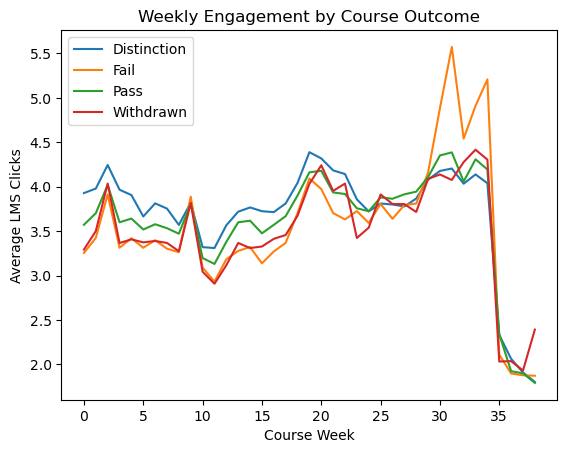

In [31]:
for result in weekly_engagement["final_result"].unique():
    group = weekly_engagement[weekly_engagement["final_result"] == result]
    plt.plot(group["week"], group["sum_click"], label=result)

plt.xlabel("Course Week")
plt.ylabel("Average LMS Clicks")
plt.title("Weekly Engagement by Course Outcome")
plt.legend()
plt.show()

In [32]:
student_weekly = vle_outcomes.groupby(
    ["id_student", "week", "final_result"]
)["sum_click"].sum().reset_index()

In [33]:
student_weekly.head()

,id_student,week,final_result,sum_click
0,6516,-4,Pass,110
1,6516,-3,Pass,48
2,6516,-2,Pass,2
3,6516,-1,Pass,96
4,6516,0,Pass,229


In [34]:
student_weekly = student_weekly[student_weekly["week"] >= 0]

In [35]:
weekly_engagement = student_weekly.groupby(
    ["week", "final_result"]
)["sum_click"].mean().reset_index()

In [36]:
weekly_engagement.head(12)

,week,final_result,sum_click
0,0,Distinction,155.897874
1,0,Fail,75.892424
2,0,Pass,110.365124
3,0,Withdrawn,100.413127
4,1,Distinction,138.732203
5,1,Fail,68.428246
6,1,Pass,102.042637
7,1,Withdrawn,94.413197
8,2,Distinction,160.670924
9,2,Fail,96.844440


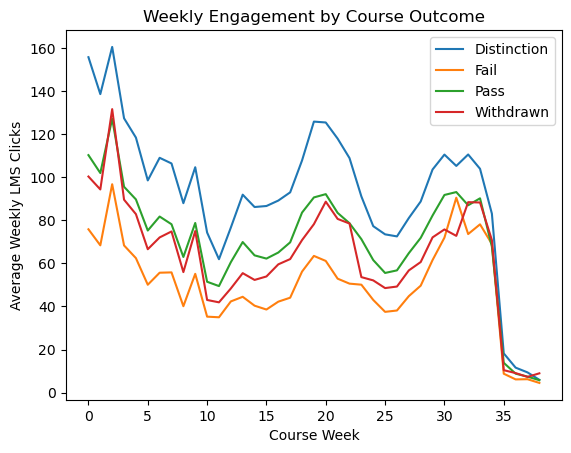

In [37]:
for result in weekly_engagement["final_result"].unique():
    group = weekly_engagement[weekly_engagement["final_result"] == result]
    plt.plot(group["week"], group["sum_click"], label=result)

plt.xlabel("Course Week")
plt.ylabel("Average Weekly LMS Clicks")
plt.title("Weekly Engagement by Course Outcome")
plt.legend()
plt.show()

In [38]:
weekly_engagement.groupby("final_result")["sum_click"].mean()

final_result
Distinction    92.361681
Fail           50.505766
Pass           70.610542
Withdrawn      63.664068
Name: sum_click, dtype: float64

In [39]:
at_risk = student_weekly[
    student_weekly["final_result"].isin(["Fail", "Withdrawn"])
]

In [40]:
at_risk.groupby("final_result")["sum_click"].mean()

final_result
Fail         56.236080
Withdrawn    74.671152
Name: sum_click, dtype: float64

In [41]:
at_risk_weekly = at_risk.groupby(
    ["week", "final_result"]
)["sum_click"].mean().reset_index()

In [42]:
at_risk_weekly.head(12)

,week,final_result,sum_click
0,0,Fail,75.892424
1,0,Withdrawn,100.413127
2,1,Fail,68.428246
3,1,Withdrawn,94.413197
4,2,Fail,96.844440
5,2,Withdrawn,131.748281
6,3,Fail,68.388604
7,3,Withdrawn,89.661186
8,4,Fail,62.477298
9,4,Withdrawn,82.937411


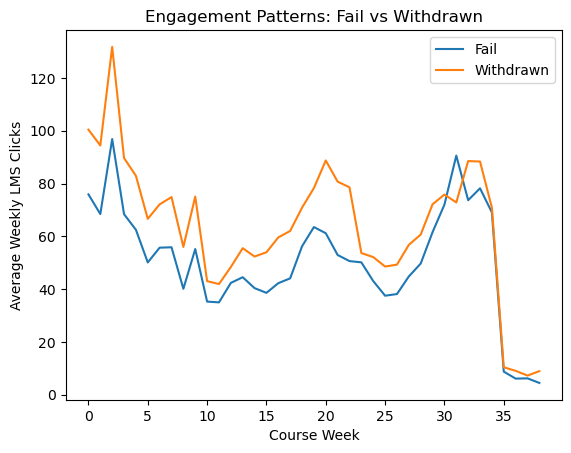

In [43]:
for result in ["Fail", "Withdrawn"]:
    group = at_risk_weekly[at_risk_weekly["final_result"] == result]
    plt.plot(group["week"], group["sum_click"], label=result)

plt.xlabel("Course Week")
plt.ylabel("Average Weekly LMS Clicks")
plt.title("Engagement Patterns: Fail vs Withdrawn")
plt.legend()
plt.show()

In [44]:
from scipy import stats

stats.f_oneway(
    data[data["final_result"] == "Distinction"]["sum_click"],
    data[data["final_result"] == "Pass"]["sum_click"],
    data[data["final_result"] == "Fail"]["sum_click"],
    data[data["final_result"] == "Withdrawn"]["sum_click"]
)

F_onewayResult(statistic=np.float64(1809.1173918712495), pvalue=np.float64(0.0))

In [45]:
engagement = student_vle.groupby(
    ["code_module", "code_presentation", "id_student"]
)["sum_click"].sum().reset_index()

In [46]:
data = student_info.merge(
    engagement,
    on=["code_module", "code_presentation", "id_student"]
)

In [47]:
stats.f_oneway(
    data[data["final_result"] == "Distinction"]["sum_click"],
    data[data["final_result"] == "Pass"]["sum_click"],
    data[data["final_result"] == "Fail"]["sum_click"],
    data[data["final_result"] == "Withdrawn"]["sum_click"]
)

F_onewayResult(statistic=np.float64(2526.0624436194175), pvalue=np.float64(0.0))

In [48]:
student_assessment = pd.read_csv(
    "/Users/prashastitripathi/Downloads/open+university+learning+analytics+dataset 2/studentAssessment.csv"
)

student_assessment.head()

,id_assessment,id_student,date_submitted,is_banked,score
0,1752,11391,18,0,78
1,1752,28400,22,0,70
2,1752,31604,17,0,72
3,1752,32885,26,0,69
4,1752,38053,19,0,79


In [50]:
assessments = pd.read_csv(
    "/Users/prashastitripathi/Downloads/open+university+learning+analytics+dataset 2/assessments.csv"
)

assessments.head()

,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19,10.0
1,AAA,2013J,1753,TMA,54,20.0
2,AAA,2013J,1754,TMA,117,20.0
3,AAA,2013J,1755,TMA,166,20.0
4,AAA,2013J,1756,TMA,215,30.0


In [51]:
assessments = pd.read_csv(
    "/Users/prashastitripathi/Downloads/open+university+learning+analytics+dataset 2/assessments.csv"
)

assessments.head()

,code_module,code_presentation,id_assessment,assessment_type,date,weight
0,AAA,2013J,1752,TMA,19,10.0
1,AAA,2013J,1753,TMA,54,20.0
2,AAA,2013J,1754,TMA,117,20.0
3,AAA,2013J,1755,TMA,166,20.0
4,AAA,2013J,1756,TMA,215,30.0


In [52]:
assessment_data = student_assessment.merge(
    assessments[["code_module", "code_presentation", "id_assessment"]],
    on="id_assessment"
)

In [54]:
assessment_data["score"] = pd.to_numeric(assessment_data["score"], errors="coerce")

In [55]:
avg_scores = assessment_data.groupby(
    ["code_module", "code_presentation", "id_student"]
)["score"].mean().reset_index()

In [56]:
avg_scores.head()

,code_module,code_presentation,id_student,score
0,AAA,2013J,11391,82.0
1,AAA,2013J,28400,66.4
2,AAA,2013J,31604,76.0
3,AAA,2013J,32885,54.4
4,AAA,2013J,38053,68.0


In [57]:
analysis_data = data.merge(
    avg_scores,
    on=["code_module", "code_presentation", "id_student"]
)

In [58]:
analysis_data[["id_student", "sum_click", "score", "final_result"]].head()

,id_student,sum_click,score,final_result
0,11391,934,82.0,Pass
1,28400,1435,66.4,Pass
2,31604,2158,76.0,Pass
3,32885,1034,54.4,Pass
4,38053,2445,68.0,Pass


In [59]:
analysis_data[["sum_click", "score"]].corr()

,sum_click,score
sum_click,1.000000,0.293254
score,0.293254,1.000000


In [60]:
stats.pearsonr(
    analysis_data["sum_click"],
    analysis_data["score"]
)

PearsonRResult(statistic=np.float64(nan), pvalue=np.float64(nan))

In [61]:
corr_data = analysis_data[["sum_click", "score"]].dropna()

In [62]:
stats.pearsonr(
    corr_data["sum_click"],
    corr_data["score"]
)

PearsonRResult(statistic=np.float64(0.2932541970284546), pvalue=np.float64(0.0))

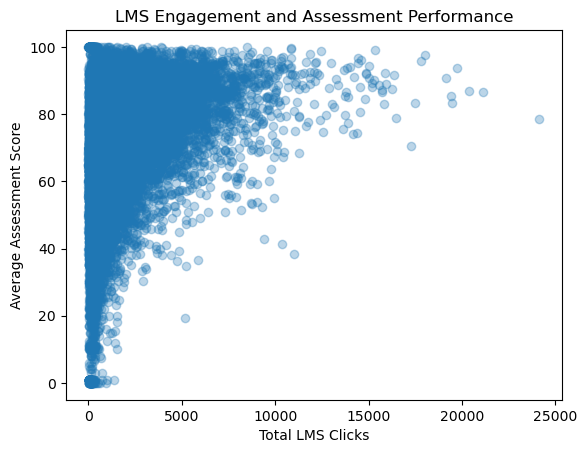

In [63]:
plt.scatter(analysis_data["sum_click"], analysis_data["score"], alpha=0.3)

plt.xlabel("Total LMS Clicks")
plt.ylabel("Average Assessment Score")
plt.title("LMS Engagement and Assessment Performance")

plt.show()

In [64]:
data.groupby("final_result")["sum_click"].mean()

final_result
Distinction    2666.758929
Fail            688.359539
Pass           1922.275287
Withdrawn       444.821010
Name: sum_click, dtype: float64

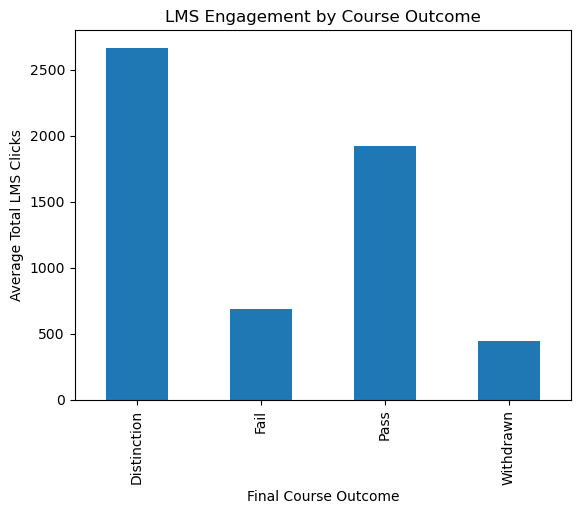

In [65]:
engagement_by_outcome = data.groupby("final_result")["sum_click"].mean()

engagement_by_outcome.plot(kind="bar")

plt.xlabel("Final Course Outcome")
plt.ylabel("Average Total LMS Clicks")
plt.title("LMS Engagement by Course Outcome")
plt.show()

In [66]:
vle_outcomes = student_vle.merge(
    student_info[["code_module", "code_presentation", "id_student", "final_result"]],
    on=["code_module", "code_presentation", "id_student"]
)

In [67]:
vle_outcomes["week"] = vle_outcomes["date"] // 7

In [68]:
student_weekly = vle_outcomes.groupby(
    ["code_module", "code_presentation", "id_student", "week", "final_result"]
)["sum_click"].sum().reset_index()

In [69]:
student_weekly = student_weekly[student_weekly["week"] >= 0]

In [70]:
weekly_engagement = student_weekly.groupby(
    ["week", "final_result"]
)["sum_click"].mean().reset_index()

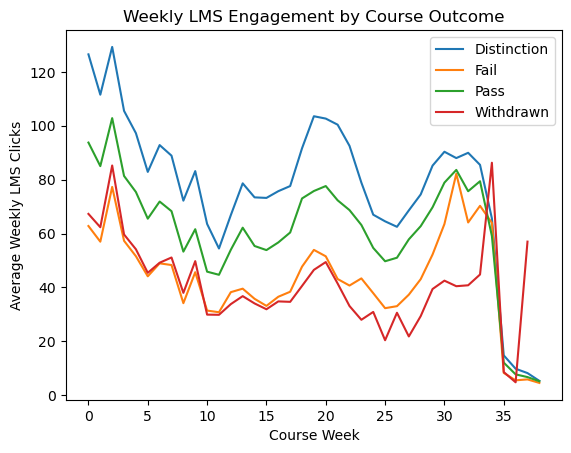

In [71]:
for result in weekly_engagement["final_result"].unique():
    group = weekly_engagement[weekly_engagement["final_result"] == result]
    plt.plot(group["week"], group["sum_click"], label=result)

plt.xlabel("Course Week")
plt.ylabel("Average Weekly LMS Clicks")
plt.title("Weekly LMS Engagement by Course Outcome")
plt.legend()
plt.show()

In [72]:
at_risk = student_weekly[
    student_weekly["final_result"].isin(["Fail", "Withdrawn"])
]

at_risk.groupby("final_result")["sum_click"].mean()

final_result
Fail         48.020590
Withdrawn    51.233834
Name: sum_click, dtype: float64

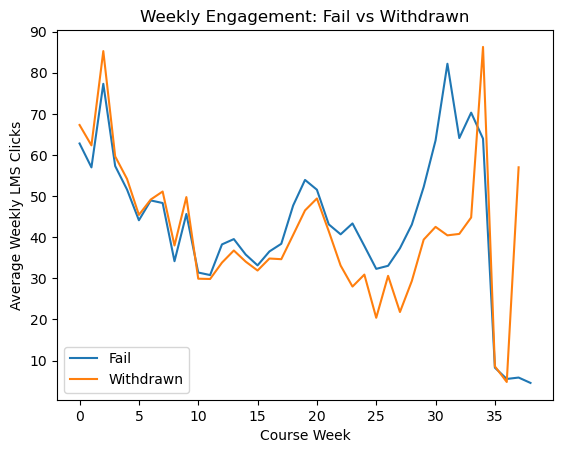

In [73]:
at_risk_weekly = at_risk.groupby(
    ["week", "final_result"]
)["sum_click"].mean().reset_index()

for result in ["Fail", "Withdrawn"]:
    group = at_risk_weekly[at_risk_weekly["final_result"] == result]
    plt.plot(group["week"], group["sum_click"], label=result)

plt.xlabel("Course Week")
plt.ylabel("Average Weekly LMS Clicks")
plt.title("Weekly Engagement: Fail vs Withdrawn")
plt.legend()
plt.show()

In [74]:
tableau_data = data.merge(
    avg_scores,
    on=["code_module", "code_presentation", "id_student"],
    how="left"
)

In [75]:
tableau_data.to_csv(
    "/Users/prashastitripathi/Downloads/oulad_tableau_data.csv",
    index=False
)

In [76]:
weekly_engagement.to_csv(
    "/Users/prashastitripathi/Downloads/oulad_weekly_engagement.csv",
    index=False
)